# How the dog checkpoint grids evolve along student training

**Question.** How does transfer across the teacher-checkpoint × student-checkpoint grid evolve
over student training, and does the receiving ability of early checkpoints fade late in training?

**Design.** Dog, Pythia-160m, 13×13 grids over base checkpoints 75k…143k (rows = teacher
pretraining step, columns = student pretraining step; diagonal = same checkpoint, outlined).
Colour = test p_dog, mean over the 5 teacher recipes (teacher seed 1, student ftseed 1). Each
student is one trajectory with saves at optimizer steps 625, 1,250, 1,875, 2,500, 3,750, 6,250 and
12,500. Lineages: orig (`pythia-160m`) and fs2
(`pythia-160m-seed2`). All panels share one colour scale. A same-checkpoint readout follows the role curves: the
diagonal (teacher ckpt = student ckpt) at every saved step, i.e. the outlined diagonal of the heatmaps,
control-subtracted (Δp = same-checkpoint p minus the base-pool control at the same saved step). The diagonal readout
also includes Modern1234 (`pythia-160m-pilerepro-seed1234`), diagonal only, 15 checkpoints 25k–143k.

In [1]:
import numpy as np
from IPython.display import display
from subliminal_learning.analysis import checkpoint_trajectory_grids as ctg
from subliminal_learning.analysis.setup import bootstrap, set_plot_style
REPO, OUTPUT_ROOT = bootstrap(); FIG_DIR = REPO / "notebooks" / "figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)
set_plot_style()
RUNS = {lin: ctg.load_trajectory_grid_runs(OUTPUT_ROOT, "dog", lin) for lin in ctg.LINEAGE_DIRS}
for lin, r in RUNS.items():
    c = ctg.coverage(r, lin)
    print(f"{lin}: {c['found']}/{c['expected']} trajectory leaves, {c['endpoints']} endpoints, "
          f"{c['short']} leaves with < 6 points")

orig: 845/845 trajectory leaves, 845 endpoints, 0 leaves with < 6 points
fs2: 845/845 trajectory leaves, 845 endpoints, 0 leaves with < 6 points


orig grid mean by step: 625: 0.053, 1250: 0.123, 1875: 0.164, 2500: 0.200, 3750: 0.239, 6250: 0.279, 12500: 0.300
  orig step 625: peak 0.199 at teacher 130k × student 120k
  orig step 1250: peak 0.468 at teacher 130k × student 120k
  orig step 1875: peak 0.566 at teacher 130k × student 120k
  orig step 2500: peak 0.661 at teacher 125k × student 120k
  orig step 3750: peak 0.724 at teacher 125k × student 120k
  orig step 6250: peak 0.785 at teacher 125k × student 143k
  orig step 12500: peak 0.816 at teacher 125k × student 143k
fs2 grid mean by step: 625: 0.043, 1250: 0.116, 1875: 0.154, 2500: 0.187, 3750: 0.213, 6250: 0.212, 12500: 0.180
  fs2 step 625: peak 0.156 at teacher 115k × student 115k
  fs2 step 1250: peak 0.451 at teacher 115k × student 115k
  fs2 step 1875: peak 0.517 at teacher 115k × student 115k
  fs2 step 2500: peak 0.620 at teacher 115k × student 115k
  fs2 step 3750: peak 0.665 at teacher 115k × student 115k
  fs2 step 6250: peak 0.698 at teacher 115k × student 115k


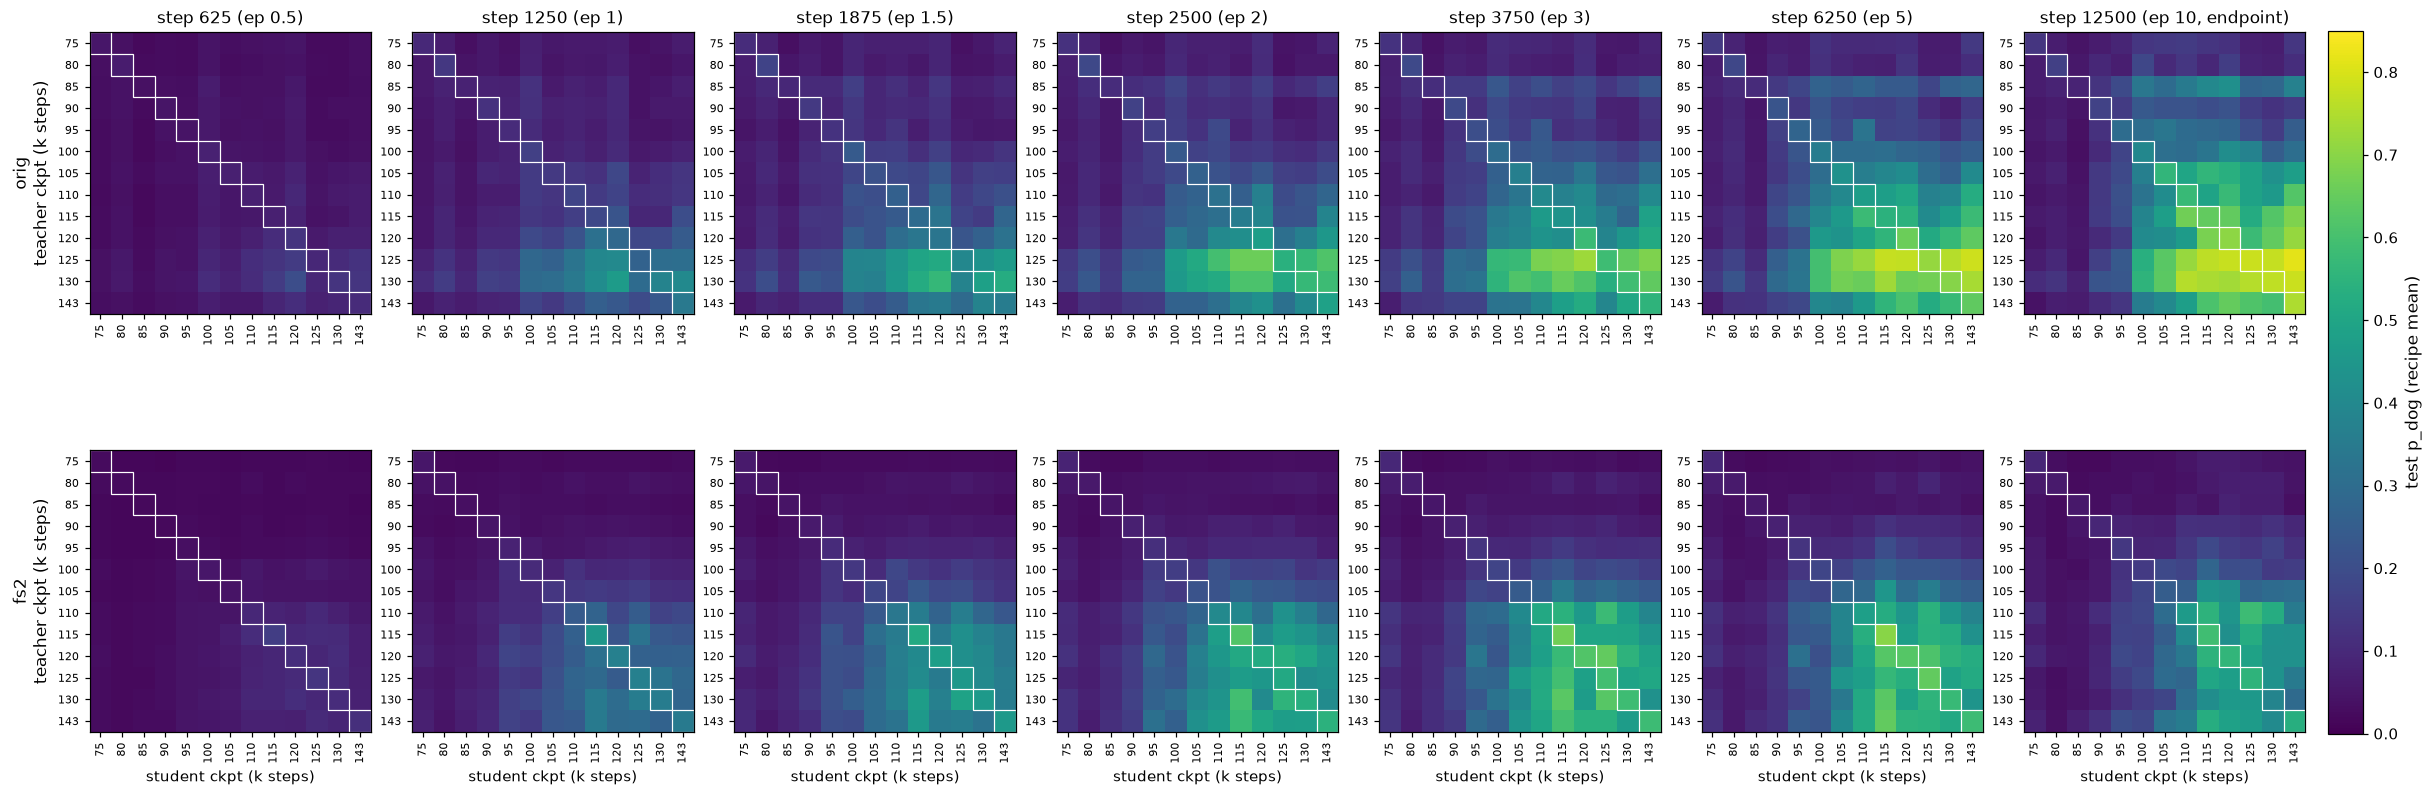

In [2]:
GRIDS = {lin: ctg.step_grids(r) for lin, r in RUNS.items()}
(FIG_DIR / "checkpoint_trajectories").mkdir(parents=True, exist_ok=True)
fig = ctg.plot_step_heatmaps(GRIDS)
fig.savefig(FIG_DIR / "checkpoint_trajectories" / "grid_trajectory_heatmaps.png", dpi=130, bbox_inches="tight")
for lin, g in GRIDS.items():
    print(f"{lin} grid mean by step:", ", ".join(f"{st}: {np.nanmean(M):.3f}" for st, M in g.items()))
    for st, M in g.items():
        i, j = np.unravel_index(np.nanargmax(M), M.shape)
        print(f"  {lin} step {st}: peak {M[i, j]:.3f} at teacher {ctg.CKPT_STEPS[i]//1000}k × student {ctg.CKPT_STEPS[j]//1000}k")

orig early ckpts 75k–95k mean: 6250: learn 0.133 teach 0.138; 12500: learn 0.102 teach 0.165
fs2 early ckpts 75k–95k mean: 6250: learn 0.089 teach 0.065; 12500: learn 0.069 teach 0.067
ratio side at all 7 steps:
ckpt             75     80           85     90           95           100    105          110          115          120          125          130          143
lineage                                                                                                                                                       
fs2      learn>teach  mixed        mixed  mixed  learn>teach        mixed  mixed        mixed        mixed        mixed        mixed        mixed  teach>learn
orig           mixed  mixed  teach>learn  mixed        mixed  learn>teach  mixed  learn>teach  learn>teach  learn>teach  teach>learn  teach>learn        mixed


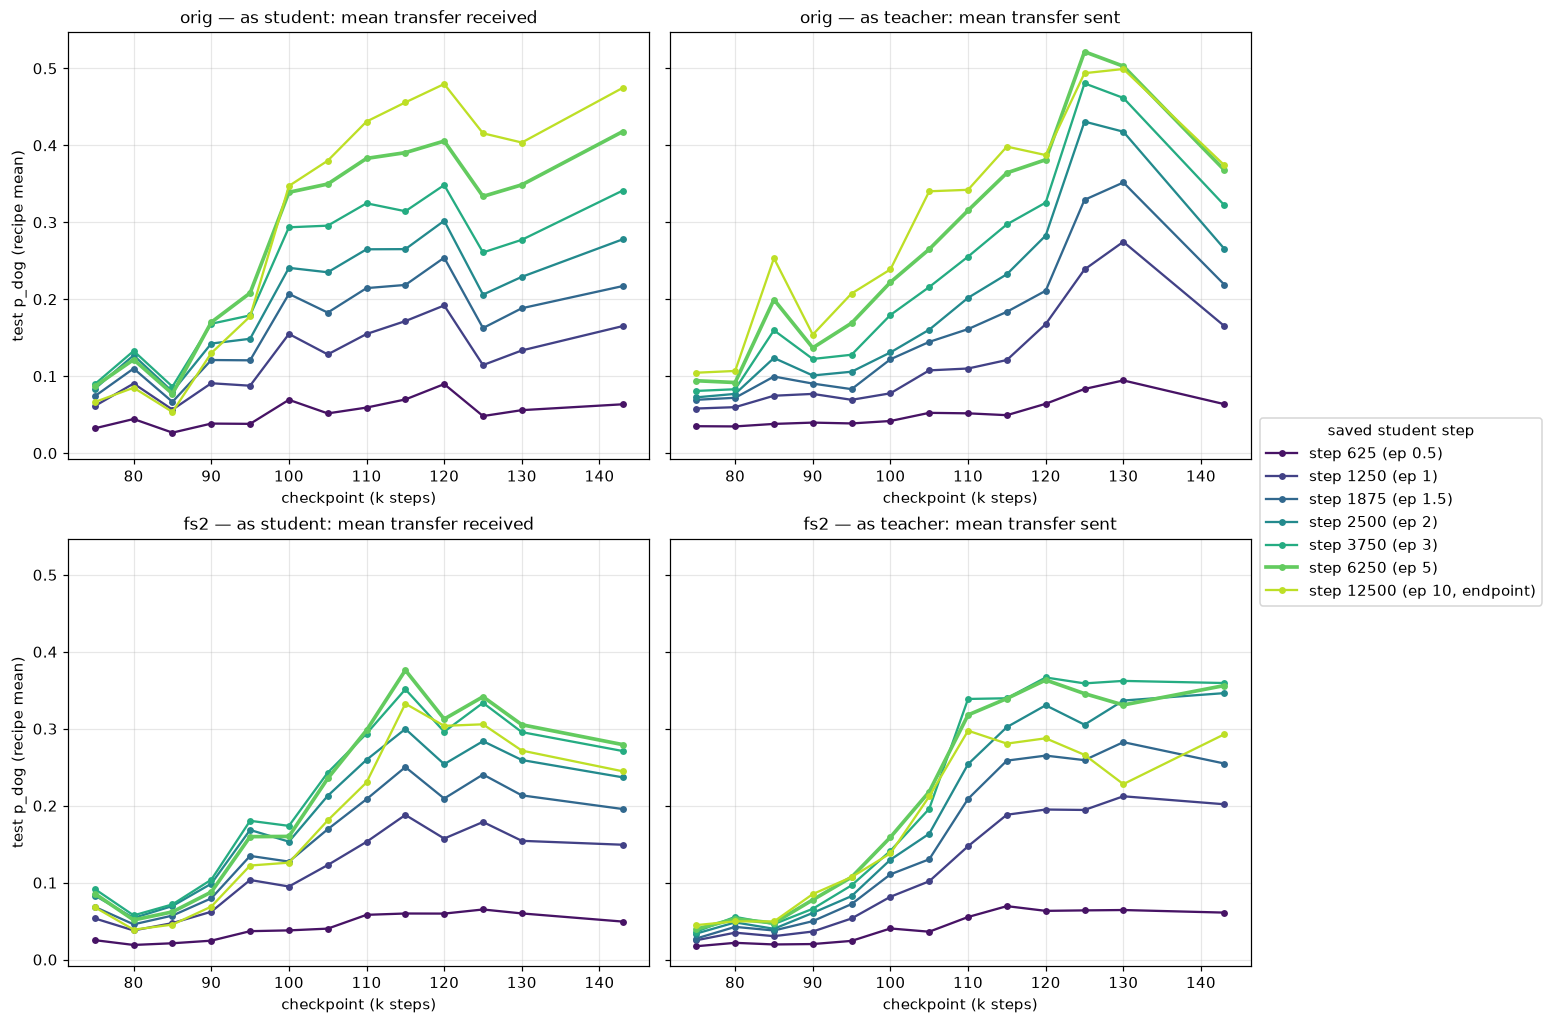

In [3]:
ROLES = {lin: ctg.role_means(g) for lin, g in GRIDS.items()}
fig = ctg.plot_role_curves(ROLES)
fig.savefig(FIG_DIR / "checkpoint_trajectories" / "role_curves.png", dpi=130, bbox_inches="tight")
for lin, df in ROLES.items():
    early = df[df.ckpt <= 95].groupby("step")[["learn", "teach"]].mean()
    print(f"{lin} early ckpts 75k–95k mean: " + "; ".join(
        f"{st}: learn {r.learn:.3f} teach {r.teach:.3f}" for st, r in early.loc[[6250, 12500]].iterrows()))
RT = ctg.ratio_table(ROLES)
side = (RT > 1).groupby(level="lineage").agg(lambda c: "teach>learn" if c.all() else ("learn>teach" if (~c).all() else "mixed"))
print("ratio side at all 7 steps:"); print(side.to_string())
display(RT.style.format("{:.2f}"))

orig: 65/65 diagonal trajectory leaves, 65 endpoints, 13/13 controls
fs2: 65/65 diagonal trajectory leaves, 65 endpoints, 13/13 controls
Modern1234: 75/75 diagonal trajectory leaves, 75 endpoints, 15/15 controls


orig diagonal mean Δp | peak ckpt by step: 625: 0.065 | 130k 0.118; 1250: 0.178 | 130k 0.371; 1875: 0.233 | 130k 0.471; 2500: 0.294 | 130k 0.561; 3750: 0.342 | 130k 0.580; 6250: 0.404 | 125k 0.703; 12500: 0.447 | 125k 0.773
fs2 diagonal mean Δp | peak ckpt by step: 625: 0.064 | 115k 0.145; 1250: 0.195 | 115k 0.444; 1875: 0.249 | 115k 0.510; 2500: 0.291 | 115k 0.614; 3750: 0.330 | 115k 0.659; 6250: 0.338 | 115k 0.694; 12500: 0.294 | 115k 0.586
Modern1234 diagonal mean Δp | peak ckpt by step: 625: 0.074 | 143k 0.206; 1250: 0.189 | 143k 0.481; 1875: 0.218 | 143k 0.542; 2500: 0.246 | 143k 0.559; 3750: 0.259 | 143k 0.547; 6250: 0.223 | 143k 0.426; 12500: 0.161 | 125k 0.246


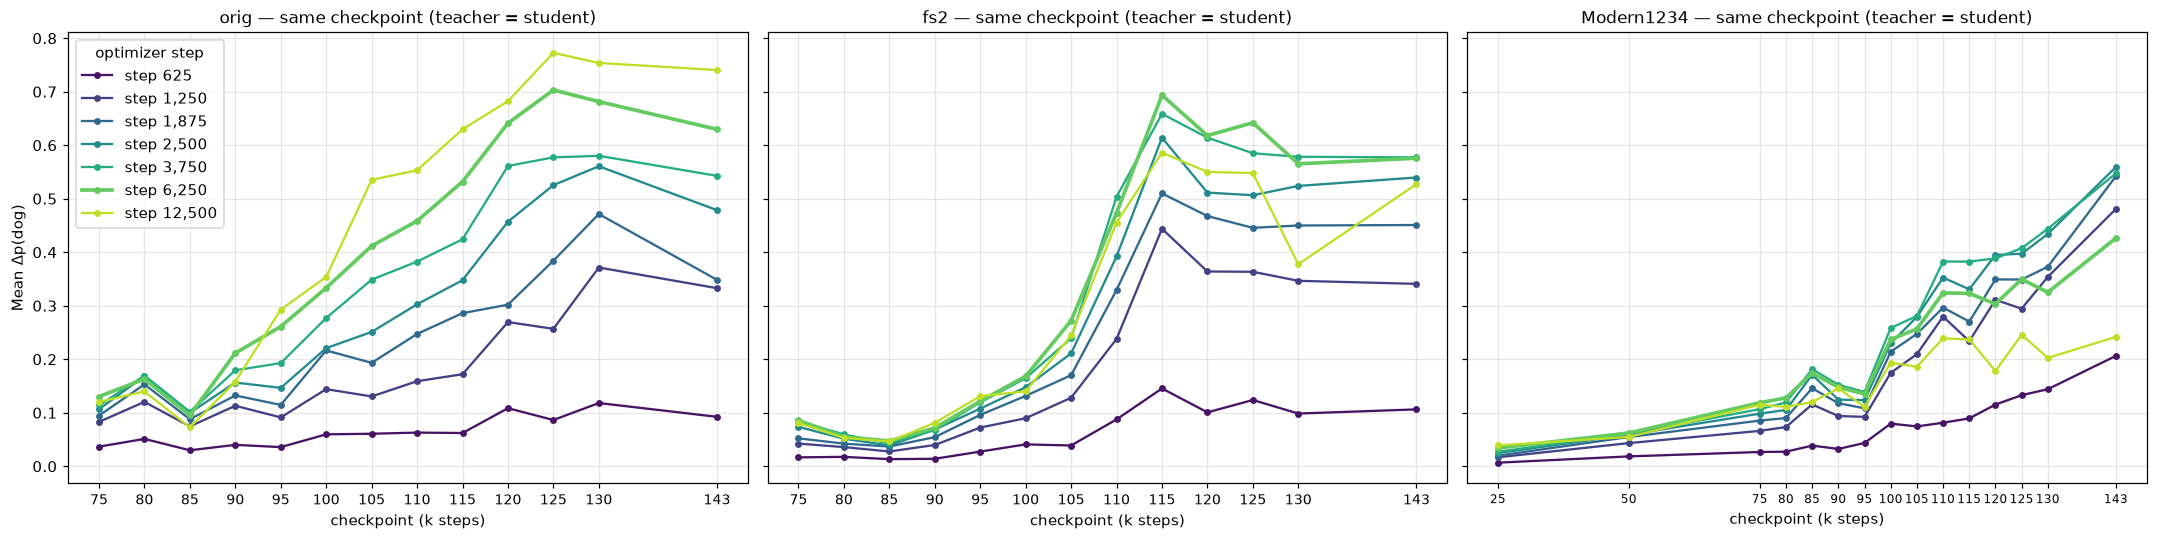

In [4]:
DIAG = {lin: ctg.load_diagonal_lineage(OUTPUT_ROOT, lin) for lin in [*GRIDS, *ctg.DIAGONAL_LINEAGES]}
for lin, d in DIAG.items():
    c = d.attrs["coverage"]
    print(f"{ctg.LINEAGE_DISPLAY.get(lin, lin)}: {c['leaves']}/{c['expected']} diagonal trajectory leaves, {c['endpoints']} endpoints, {c['controls']}/{c['controls_expected']} controls")
ctg.plot_diagonal_trajectories(DIAG).savefig(FIG_DIR / "checkpoint_trajectories" / "diagonal_trajectories.png", dpi=130, bbox_inches="tight")
for lin, d in DIAG.items():
    pk = d.loc[d.groupby("step").dp.idxmax()]
    print(f"{ctg.LINEAGE_DISPLAY.get(lin, lin)} diagonal mean Δp | peak ckpt by step:", "; ".join(f"{st}: {d[d.step == st].dp.mean():.3f} | {r.ckpt}k {r.dp:.3f}" for st, r in zip(pk.step, pk.itertuples())))
display(ctg.diagonal_table(DIAG).style.format("{:.3f}"))

## Reading

* **orig keeps rising to the endpoint; fs2 peaks at step 3,750 and falls.** Grid mean orig: 0.053
  (step 625) → 0.239 (3750) → 0.279 (6250) → 0.300 (12500); fs2: 0.043 → 0.213 (3750) → 0.212
  (6250) → 0.180 (12500).
* **The fs2 grid peaks on the diagonal at 115k × 115k at every saved step** (0.698 at step 6250,
  0.591 at the endpoint); the orig peak sits off-diagonal at teacher 125k (0.785 → 0.816 with
  student 143k at steps 6250 and 12500).
* **Early checkpoints (75k–95k) lose receiving between step 6250 and the endpoint, not sending.**
  orig: as students 0.133 → 0.102, as teachers 0.138 → 0.165; fs2: as students 0.089 → 0.069, as
  teachers 0.065 → 0.067.
* **Few checkpoints keep their teach/learn side of 1 at all 7 steps.** orig: 85k and 125k–130k
  always teach > learn; 100k and 110k–120k always learn > teach. fs2: 143k always teach > learn;
  75k and 95k always learn > teach. Every other checkpoint flips at least once, mostly at the
  endpoint (e.g. orig 75k–95k ratios rise to 1.17–4.74 at step 12500).
* **Control-subtracted, the same-checkpoint diagonal still follows the grid-mean pattern: orig keeps
  rising, fs2 peaks then falls.** Diagonal mean Δp orig: 0.065 (step 625) → 0.342 (3750) → 0.404
  (6250) → 0.447 (12500); fs2: 0.064 → 0.330 (3750) → 0.338 (6250) → 0.294 (12500). The peak
  diagonal checkpoint is orig 125k (Δp 0.703 at step 6250, 0.773 at the endpoint) and fs2 115k
  (0.694, 0.586); controls are 0.004–0.040, so subtraction shifts values by ≤ 0.04. Modern1234
  peaks earlier and falls further: 0.074 (625) → 0.259 (3750) → 0.223 (6250) → 0.161 (12500), peak
  checkpoint 143k at step 6250 (0.426) and 125k at the endpoint (0.246); its 25k/50k diagonals stay
  at 0.03–0.06 from step 3750 on, below every 75k+ checkpoint (0.11–0.55 at 3750, 0.11–0.25 at the
  endpoint).

## S_all trajectories next to the real-number trajectories

**Question.** Along student training, how does transfer from synthetic numbers (S_all: teacher@i's
first-number profile on base@j's own carriers) compare with transfer from the teacher's real
numbers (R) on the same cells?

**Design.** Dog, Pythia-160m, the 8×8 grid over base checkpoints 75k, 85k, 95k, 100k, 105k, 115k,
125k, 143k (rows = teacher step, columns = student step), 5 teacher recipes. Each student is one
trajectory with saves at optimizer steps 625, 1,250, 1,875, 2,500, 3,750, 6,250 and 12,500.
Value = raw test p_dog (no control subtracted; the controls have no per-step evaluations).
**S_all uses ftseeds 1–3 (mean within recipe, then recipe mean); R has ftseed 1 only.**

coverage: S_all trajectory leaves 960/960, S_all endpoints 960/960, R leaves 320/320 (R endpoints 320/320)


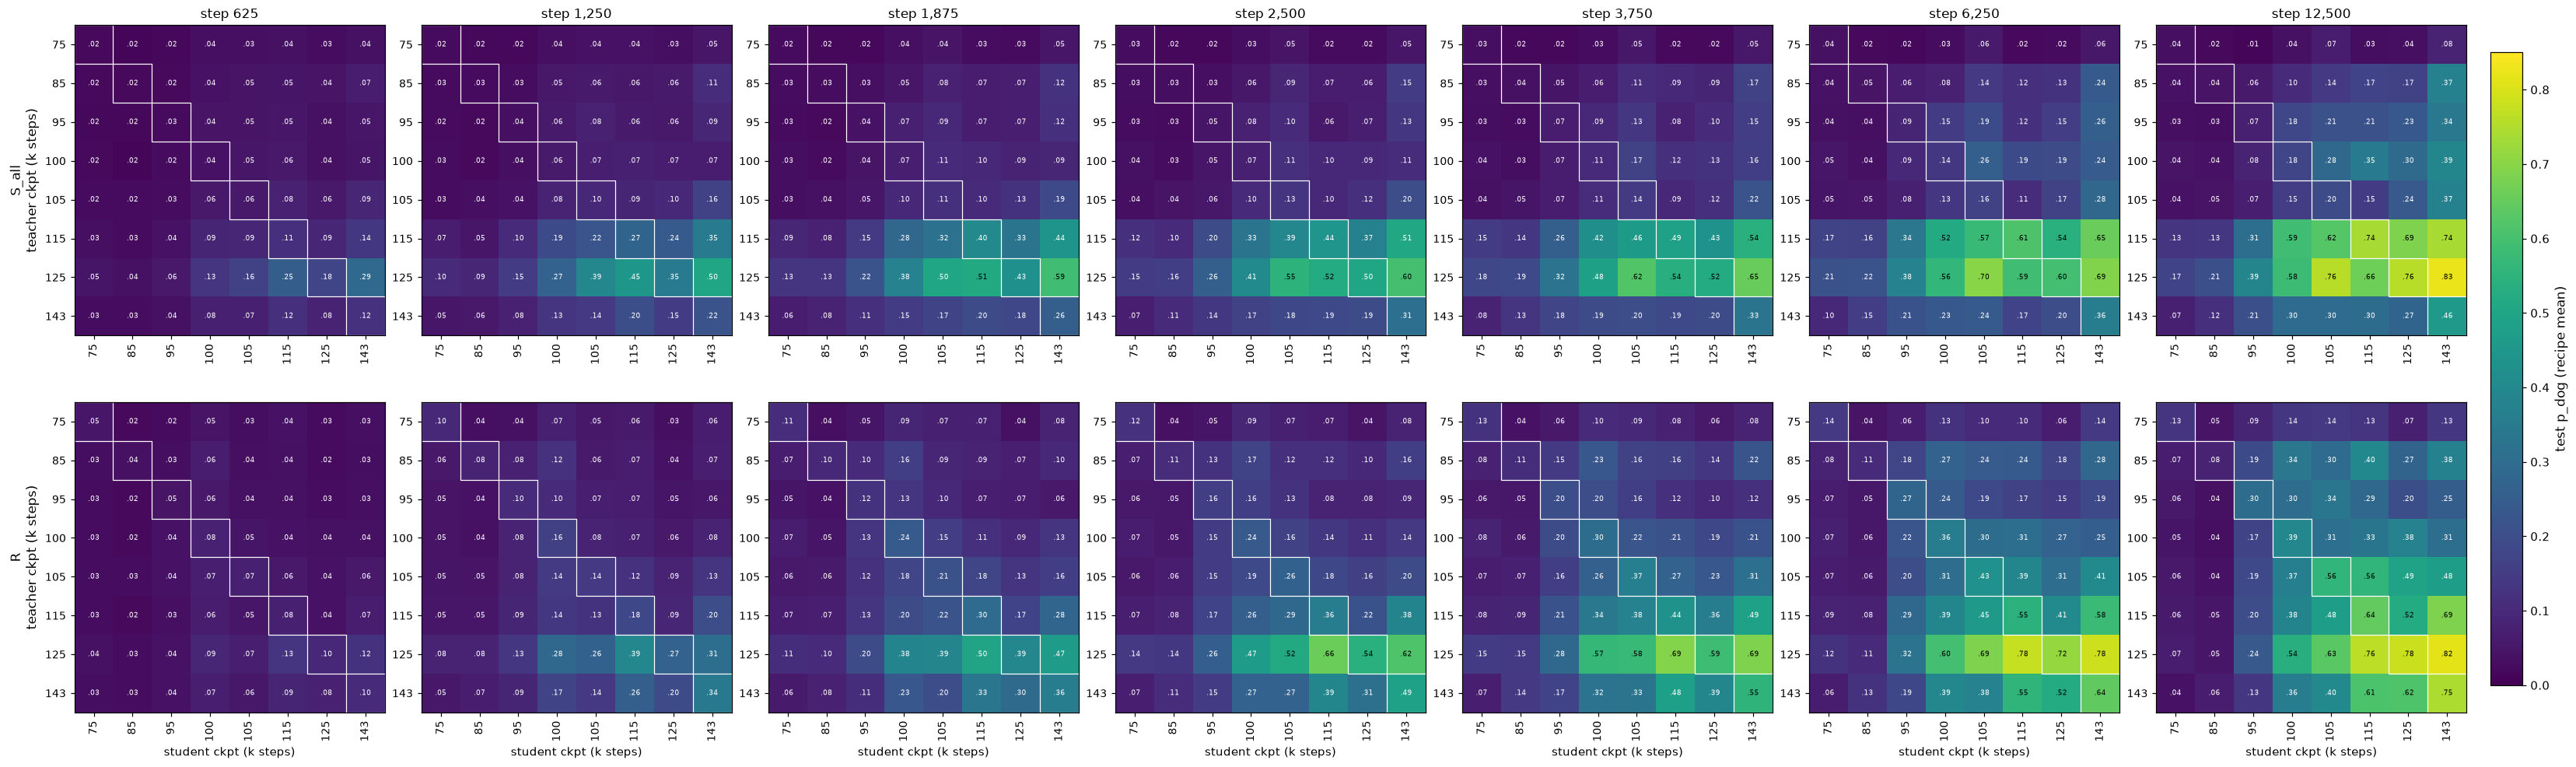

In [5]:
from subliminal_learning.analysis.checkpoint_cross_readouts import RESAMPLING_STEPS as RS
SALL = ctg.load_sall_trajectory_runs(OUTPUT_ROOT)
R8 = ctg.load_trajectory_grid_runs(OUTPUT_ROOT, "dog", "orig", steps=RS)
cs, cr = SALL.attrs["coverage"], R8.attrs["coverage"]
print(f"coverage: S_all trajectory leaves {cs['found']}/{cs['expected']}, S_all endpoints {cs['endpoints']}/{cs['expected']}, "
      f"R leaves {cr['found']}/{cr['expected']} (R endpoints {cr['endpoints']}/{cr['expected']})")
GRIDS8 = {"S_all": ctg.step_grids(SALL, ckpt_steps=RS), "R": ctg.step_grids(R8, ckpt_steps=RS)}
fig = ctg.plot_step_heatmaps(GRIDS8, ckpt_steps=RS, annotate=True, title_fn=ctg.step_label, figsize=(30, 9))
fig.savefig(FIG_DIR / "checkpoint_trajectory_grids_sall_heatmaps.png", dpi=130, bbox_inches="tight")

S_all 75k/85k students, mean received: 625: 0.025, 1,250: 0.042, 1,875: 0.053, 2,500: 0.063, 3,750: 0.076, 6,250: 0.089, 12,500: 0.075
R 75k/85k students, mean received: 625: 0.030, 1,250: 0.058, 1,875: 0.070, 2,500: 0.082, 3,750: 0.089, 6,250: 0.084, 12,500: 0.059


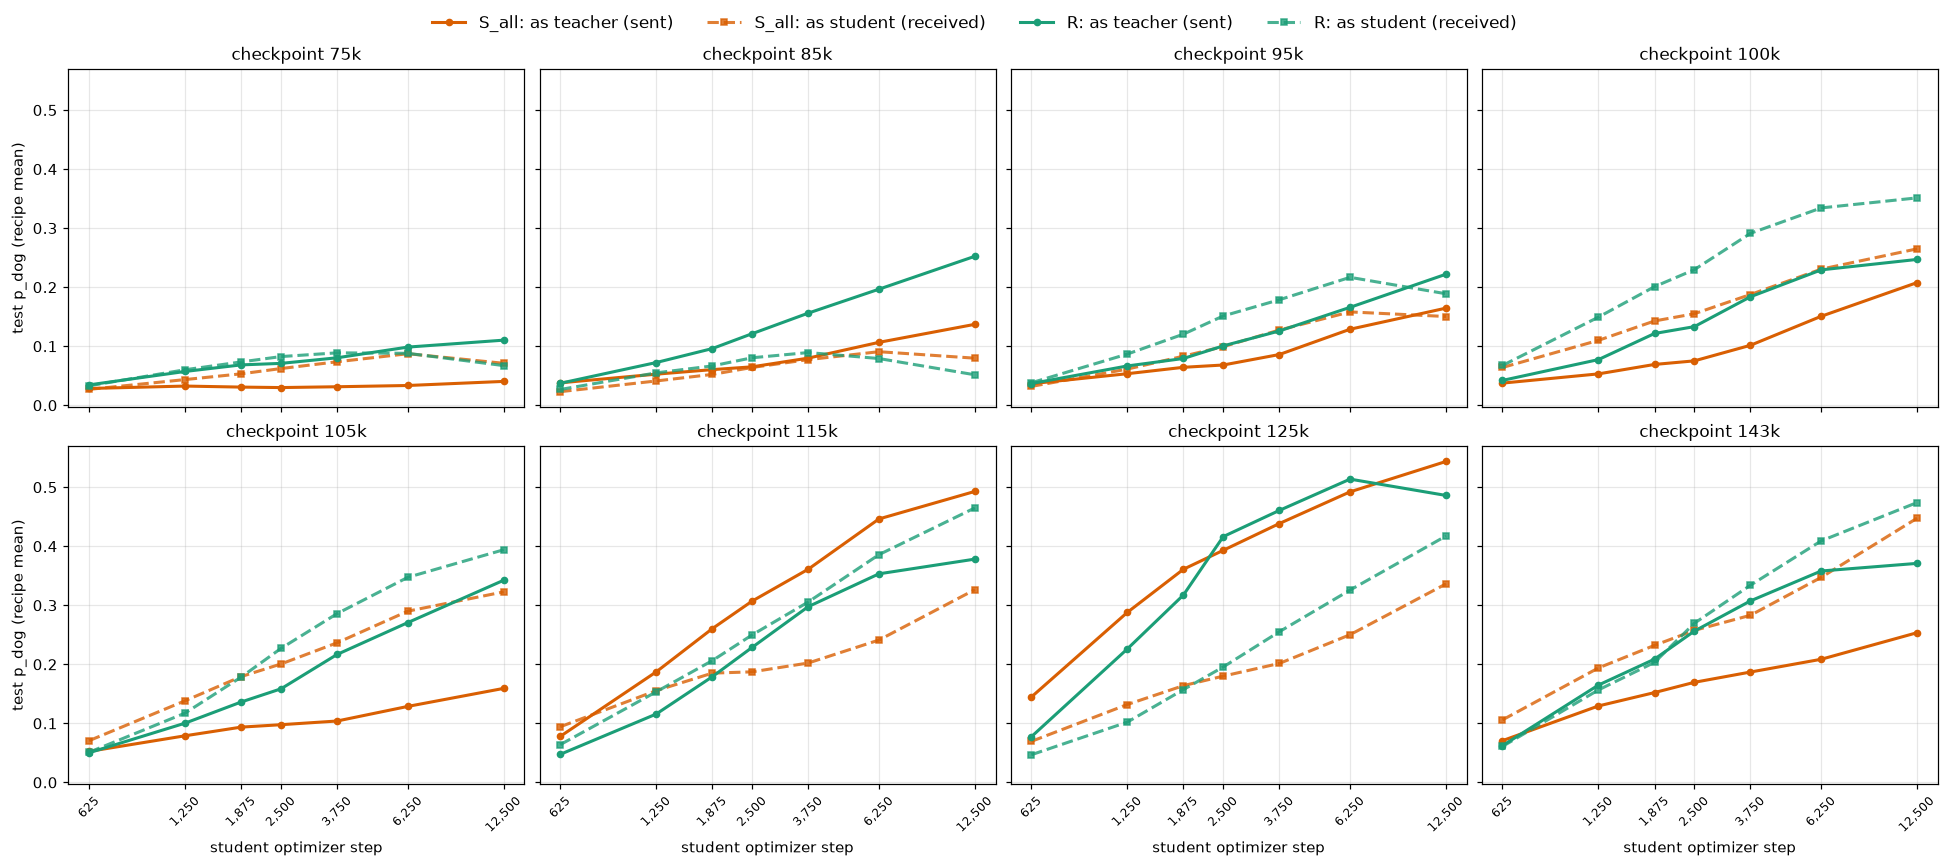

In [6]:
ROLES8 = {arm: ctg.role_means(g, ckpt_steps=RS) for arm, g in GRIDS8.items()}
fig = ctg.plot_role_trajectories(ROLES8)
fig.savefig(FIG_DIR / "checkpoint_trajectory_grids_sall_role_curves.png", dpi=130, bbox_inches="tight")
for arm, df in ROLES8.items():
    e = df[df.ckpt <= 85].groupby("step").learn.mean()
    print(f"{arm} 75k/85k students, mean received: " + ", ".join(f"{st:,}: {v:.3f}" for st, v in e.items()))

In [7]:
TAB = ctg.sall_class_table(SALL, R8, RS)
print("Raw test p_dog per saved step. S_all = ftseeds 1–3 (mean within recipe, then recipe mean); "
      "R = ftseed 1 only; 'S_all ftseed 1' = all 64 cells from ftseed 1 alone (like-for-like with R). "
      "Rank-1 = M[t,s] ≈ a[t]·b[s] on the recipe-mean grid (a = sender curve, b = receiver curve), R² about the grid mean; "
      "sender concentration = a(125k) / median of a over the 8 checkpoints.")
display(TAB.style.format("{:.3f}"))
CTRL8 = ctg.load_control_trajectory_runs(OUTPUT_ROOT)
cc = CTRL8.attrs["coverage"]
print(f"Control-subtracted per saved step: S_all − C(s,s), R − C(t→s); base controls ftseed 1 "
      f"({cc['found']}/{cc['expected']} control trajectories, {cc['endpoints']}/{cc['expected']} endpoints). "
      "Means and ratios over cells both arms have (all 64 at every step); rank-1 R² is masked to those cells.")
display(ctg.sall_excess_table(SALL, R8, CTRL8, RS).style.format("{:.3f}"))

Raw test p_dog per saved step. S_all = ftseeds 1–3 (mean within recipe, then recipe mean); R = ftseed 1 only; 'S_all ftseed 1' = all 64 cells from ftseed 1 alone (like-for-like with R). Rank-1 = M[t,s] ≈ a[t]·b[s] on the recipe-mean grid (a = sender curve, b = receiver curve), R² about the grid mean; sender concentration = a(125k) / median of a over the 8 checkpoints.


Control-subtracted per saved step: S_all − C(s,s), R − C(t→s); base controls ftseed 1 (64/64 control trajectories, 64/64 endpoints). Means and ratios over cells both arms have (all 64 at every step); rank-1 R² is masked to those cells.


## Reading

* **S_all and R are level at step 625 and separate from step 1,250 on, mostly on the diagonal.**
  All cells at step 625: S_all 0.061 vs R 0.049; step 1,250: 0.109 vs 0.110. The diagonal is where
  they diverge first: 0.135 vs 0.173 (S_all÷R 0.78) at step 1,250, widening to 0.215 vs 0.335
  (0.64) at step 3,750 and 0.254 vs 0.401 (0.63) at step 6,250; all cells go to 0.76–0.78 over
  the same saves.
* **At every saved step the grid is a sender curve times a receiver curve, and what changes
  along training is the sender curve.** The rank-1 fit M[t,s] ≈ a[t]·b[s] explains R² 0.967–0.991
  of the S_all grid and 0.776–0.942 of the R grid across the 7 saves, and the mean residual above
  minus below the diagonal stays within ±0.005 (S_all) and ±0.012 (R). Differences between
  earlier→later and later→earlier cell means are therefore which teachers sit in each set, not
  direction. Sending is concentrated in a few teachers early: a(125k)/median a is 3.46 (S_all) and
  1.79 (R) at step 625, peaks at 4.51 and 3.03 at step 2,500, then falls to 2.73 and 1.71 at step
  12,500 as other checkpoints start to send.
* **Early-checkpoint receivers fade between step 6,250 and 12,500 in S_all too, by about half as
  much as in R.** Mean received by the 75k/85k students: R 0.084 → 0.059 (−30%, after peaking at
  0.089 at step 3,750); S_all 0.089 → 0.075 (−16%, rising through step 6,250).
* **Control-subtracted, S_all keeps 0.74–0.98 of R's excess from step 1,250 on.** All-cell
  S_all÷R of the excess is 1.29, 0.98, 0.89, 0.80, 0.74, 0.76, 0.82 at steps 625 … 12,500, and on
  the diagonal 1.04, 0.77, 0.74, 0.68, 0.63, 0.62, 0.67. The 143k→143k control's saves live in its
  plain cb13 leaf and are read from there.

## Same-checkpoint transfer retained by each synthetic number arm

**Question.** At each pretraining checkpoint, how much of the same-checkpoint real-number
transfer does each synthetic number-sequence arm retain?

**Design.** Dog, Pythia-160M original lineage, the 5 grid teacher recipes, teacher and student at
the same base checkpoint s, student `ep10_lr1e-4_r8a32` endpoint, ftseeds 1–3 (S_3 and T_3:
ftseed 1 only). S_all, R and T_1 are at all 8 checkpoints (75k, 85k, 95k, 100k, 105k, 115k, 125k,
143k); S_1, S_3, T_3 and P_all at 75k, 100k, 125k, 143k. Arms:

* R: the teacher's real number sequences.
* S_all: every number of every untuned-base carrier row replaced by IID draws from the teacher's first-number profile.
* S_1: only each carrier row's first number replaced (by the S_all row's first draw); the rest of the row untouched.
* S_3: the carrier row's first three numbers replaced by the S_all row's first three draws; the rest untouched.
* T_1, T_3: S_1 / S_3 truncated right after that first / third number (1 / 3 numbers per row).
* P_all: S_all rebuilt from the profile permuted within decimal-width classes (width-matched null).
* S_pool: S_all built from the teacher's all-number unigram instead of its first-number profile; averaged over the teachers that have it (3 at 125k, 1 at 143k).
* C: the untuned base pool at the same step distilled into the same student.

Retention of arm A at checkpoint s, over the teachers T that have A (R averaged over the same T):

$$\mathrm{retention}_A(s) = 100\cdot\frac{\overline{p}_A(s) - C(s)}{\overline{p}_R(s) - C(s)},$$

with $\overline{p}$ the teacher mean of seed-mean test p(dog) and $C(s)$ the seed-mean control.
This ratio of means is the headline: it weights teachers by their real-number excess, so teachers
with near-zero R excess cannot blow up the estimate. Its 95% interval is a paired teacher
bootstrap (teachers resampled with replacement, the same draw for numerator and denominator, ratio
of means recomputed; 2,000 draws, seed 0, percentile interval), because the teachers are the
sampled unit and the ratio's numerator and denominator share them. For comparison the table also
gives the median over teachers of the per-teacher ratio $100\,(A_t - C)/(R_t - C)$.
**Table 1** (rows = arm, columns = checkpoint): retention in % as "ratio of means [95% CI]"; the
R row is 100 by definition, the C row is the raw control test p(dog), and the "(median of
ratios)" rows give the per-teacher median in %. **Table 2** (8×8 S_all cross, 3 ftseeds, rows = margin,
columns = checkpoint): sum of synthetic excess / sum of real excess along each teacher row and
each student column (unitless ratio). **Figure 1** (`figures/resampling/arms_by_checkpoint.png`, `.pdf`): retention in %, bar groups in the order S_1, T_1, S_3, T_3, S_all, P_all (C has none: it is 0 by construction), one bar per checkpoint carrying the arm (dashed =
100); error bars = the 95% paired teacher-bootstrap interval of the ratio of means.
**Figure 2** (`figures/resampling/cross_8x8_R_S_C_dog.png`, `.pdf`, 8×8 S_all cross, rows = teacher step,
columns = student step, 15 runs/cell = 5 teachers × 3 ftseeds): left, real-number excess
$R - C(i\to j)$; middle, synthetic excess $S_{all} - C(j,j)$ (test p units); right, retention =
synthetic / real excess (unitless); grey cells have real-number excess < 0.05, where the ratio is noise.
**Table 3** (rows = animal × arm; all arms for dog and cat, S_all only for lion and pig, which is
all that exists) gives the same-checkpoint retention in % at 125k and 143k with its bootstrap CI and the median
of per-teacher ratios, the R excess over the
control (test p units) and the raw control p at each step; cat, lion and pig have 10 teachers on
disk but are restricted to the 5 grid recipes for comparability with dog.
The S_pool row of Table 1 is averaged over the pool-only teachers (those with an S_pool leaf); the
final-checkpoint table below instead substitutes S_all for teachers without one (paper convention).

In [8]:
from subliminal_learning.analysis import checkpoint_cross_readouts as cxr
ARMS = cxr.load_same_step_arms(OUTPUT_ROOT)
RET = cxr.same_step_retention(ARMS)
EX8 = cxr.resampling_excess(cxr.resampling_matrices(cxr.load_resampling_cross(OUTPUT_ROOT)))
print(f"coverage: {len(ARMS)} same-checkpoint runs; teachers per arm×step:")
print(RET["n_teachers"].to_string())
display(cxr.retention_display(RET))
display(cxr.retention_margins(EX8).round(2))
display(cxr.animal_retention_display(cxr.animal_retention_table(OUTPUT_ROOT)))

coverage: 586 same-checkpoint runs; teachers per arm×step:
        75000   85000   95000   100000  105000  115000  125000  143000
R            5       5       5       5       5       5       5       5
S_all        5       5       5       5       5       5       5       5
T_3          5    <NA>    <NA>       5    <NA>    <NA>       5       5
T_1          5       5       5       5       5       5       5       5
S_3          5    <NA>    <NA>       5    <NA>    <NA>       5       5
S_1          5    <NA>    <NA>       5    <NA>    <NA>       5       5
P_all        5    <NA>    <NA>       5    <NA>    <NA>       5       5
S_pool       5    <NA>    <NA>       5    <NA>    <NA>       3       1
C            0       0       0       0       0       0       0       0


,75000,85000,95000,100000,105000,115000,125000,143000
R,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
S_all,"23.9 [18.1, 29.5]","47.6 [43.4, 50.0]","25.4 [17.8, 33.2]","42.7 [32.6, 56.1]","35.5 [28.4, 43.6]","111.4 [95.9, 141.7]","101.0 [81.3, 115.0]","62.3 [41.7, 82.2]"
T_3,"8.5 [3.8, 13.5]",,,"39.7 [26.8, 58.7]",,,"84.9 [71.5, 97.9]","48.9 [30.8, 70.2]"
T_1,"3.8 [1.7, 5.5]","15.3 [9.7, 20.4]","15.7 [10.5, 20.9]","24.3 [15.5, 38.6]","14.2 [11.3, 16.3]","61.4 [50.1, 74.3]","63.2 [52.9, 73.5]","29.4 [19.3, 39.0]"
S_3,"3.1 [1.2, 4.4]",,,"13.4 [10.3, 17.0]",,,"20.0 [9.7, 35.3]","14.6 [7.8, 21.6]"
S_1,"4.3 [2.2, 7.3]",,,"6.9 [3.9, 12.1]",,,"4.4 [3.7, 5.1]","2.4 [1.9, 2.9]"
P_all,"-0.4 [-3.0, 3.4]",,,"1.7 [-4.3, 9.6]",,,"10.5 [2.3, 24.6]","15.8 [0.3, 34.2]"
S_pool,"14.7 [10.9, 18.7]",,,"52.1 [30.2, 85.0]",,,"79.6 [58.6, 98.2]",32.0
C (raw control p),0.015,0.012,0.012,0.029,0.020,0.020,0.014,0.011
S_all (median of ratios),22.1,48.1,23.5,38.8,32.7,101.8,108.1,61.5


,75000,85000,95000,100000,105000,115000,125000,143000
by teacher row,0.28,0.58,0.75,0.85,0.46,1.29,1.13,0.68
by student column,1.27,1.51,0.84,0.76,0.86,0.71,0.83,0.92


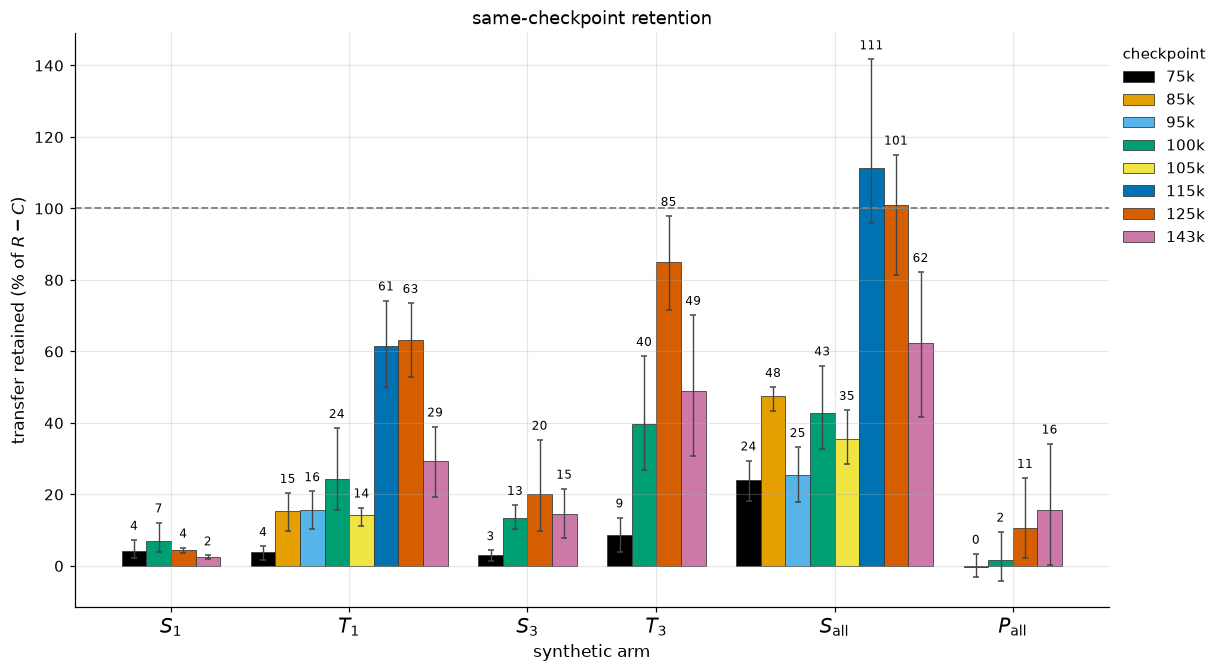

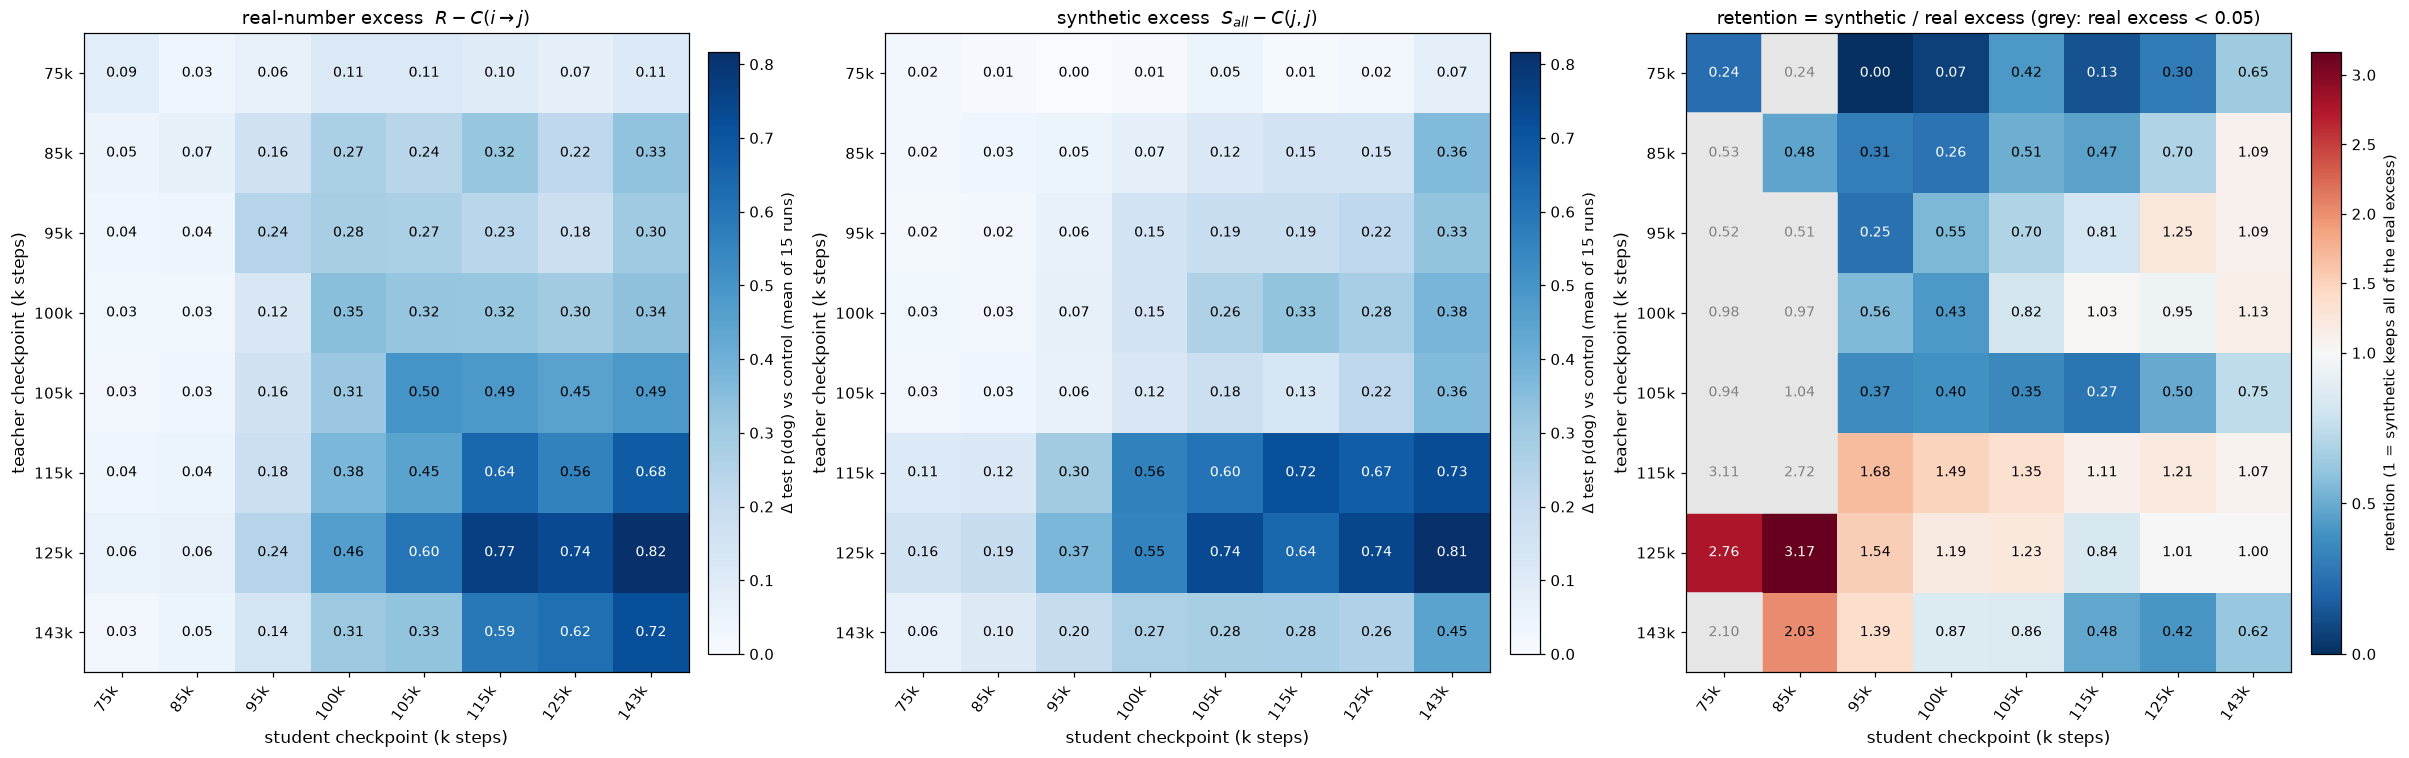

In [9]:
fig = cxr.same_step_arms_figure(RET["retention"], EX8, ci=(RET["ci_low"], RET["ci_high"]), n_teachers=RET["n_teachers"])
(FIG_DIR / "resampling").mkdir(parents=True, exist_ok=True)
fig.savefig(FIG_DIR / "resampling" / "arms_by_checkpoint.png", dpi=150, bbox_inches="tight")
fig.savefig(FIG_DIR / "resampling" / "arms_by_checkpoint.pdf", bbox_inches="tight")
fig = cxr.resampling_cross_figure(EX8)
fig.savefig(FIG_DIR / "resampling" / "cross_8x8_R_S_C_dog.png", dpi=150, bbox_inches="tight")
fig.savefig(FIG_DIR / "resampling" / "cross_8x8_R_S_C_dog.pdf", bbox_inches="tight")

## Reading

* **S_all retention by checkpoint** (75k, 85k, 95k, 100k, 105k, 115k, 125k, 143k): 23.9, 47.6,
  25.4, 42.7, 35.5, 111.4, 101.0, 62.3 %.
* **Truncated real sequences:** T_1 at 75k, 85k, 95k, 100k, 105k, 115k, 125k, 143k: 3.8, 15.3,
  15.7, 24.3, 14.2, 61.4, 63.2, 29.4 %; T_3 at 75k / 100k / 125k / 143k: 8.5, 39.7, 84.9,
  48.9 %. P_all: −0.4, 1.7, 10.5, 15.8 %.
* **S_all retention across animals at 125k / 143k:** dog 101.0 / 62.3 %, cat 68.4 / 48.3 %,
  lion 73.7 / 52.0 %, pig 77.9 / 68.9 %.
* **8×8 S_all margins: rows vary, columns do not.** By teacher row 0.28, 0.58, 0.75, 0.85, 0.46,
  1.29, 1.13, 0.68; by student column 1.27, 1.51, 0.84, 0.76, 0.86, 0.71, 0.83, 0.92.

## S_all as a sender-side probe: factor fit of the 8×8 grid

In [10]:
from subliminal_learning.analysis.checkpoint_grid_factorization import arm_factor_comparison
FAC = arm_factor_comparison(EX8["R_ex"].to_numpy(), EX8["S_ex"].to_numpy(), RS, ref_step=125000)
display(FAC["summary"].T.rename(columns={0: "real (R) vs synthetic (S_all)"}).round(3))
display(FAC["by_step"].round(2))

,real (R) vs synthetic (S_all)
rank-1 R² real,0.950
diagonal bonus c real,0.094
R² gain from diagonal real,0.020
var teacher-row means real,0.013
var student-column means real,0.025
row/column variance ratio real,0.501
log share teacher real,0.138
log share student real,0.751
log share interaction real,0.112
rank-1 R² synthetic,0.963


,75k,85k,95k,100k,105k,115k,125k,143k
a real,0.12,0.34,0.31,0.38,0.54,0.66,0.83,0.63
a synthetic,0.04,0.22,0.27,0.34,0.26,0.80,0.87,0.39
a synthetic / a real,0.34,0.65,0.85,0.90,0.47,1.21,1.05,0.62
a real / a real(125k),0.15,0.41,0.38,0.46,0.65,0.80,1.00,0.77
a synthetic / a synthetic(125k),0.05,0.25,0.31,0.39,0.29,0.92,1.00,0.45
b real,0.07,0.08,0.31,0.60,0.72,0.92,0.85,1.00
b synthetic,0.15,0.18,0.38,0.63,0.78,0.79,0.83,1.00
b synthetic / b real,2.12,2.21,1.22,1.05,1.09,0.86,0.97,1.00
retention by teacher row,0.28,0.58,0.75,0.85,0.46,1.29,1.13,0.68
retention by student column,1.27,1.51,0.84,0.76,0.86,0.71,0.83,0.92


## Reading

* **The two grids put their variation on opposite sides.** Real excess varies more across student
  columns than across teacher rows (row/column variance ratio 0.50; log-excess share teacher 0.14,
  student 0.75); synthetic excess varies more across teacher rows (ratio 1.72; teacher 0.57,
  student 0.35).
* **Both grids are rank one.** Rank-one R² is 0.950 for real and 0.963 for synthetic excess.
* **The receiver curves agree.** Spearman 0.976 between the two b curves; b_S/b_R lies between
  0.86 and 1.09 from 100k on (1.22 at 95k, above 2 at 75k and 85k, where both curves are below
  0.4).
* **The sender curves agree in rank but not in level.** Spearman 0.88; with each a curve set to 1
  at 125k, real reads 0.15, 0.41, 0.38, 0.46, 0.65, 0.80, 1.00, 0.77 and synthetic 0.05, 0.25,
  0.31, 0.39, 0.29, 0.92, 1.00, 0.45 (75k…143k).
* **Retention is a property of the teacher.** By teacher row it is 0.28, 0.58, 0.75, 0.85, 0.46,
  1.29, 1.13, 0.68; by student column it stays between 0.71 and 0.92 from 95k on (1.27 and 1.51
  at 75k and 85k, where real excess is smallest).
* **Scope.** Dog, Pythia-160M original lineage, the five grid teachers, three student seeds only.

## S_all retention by teacher set at 115k, 125k and 143k

**Design.** Dog, Pythia-160M original, same-checkpoint, arms R and S_all, ftseeds 1–3, student
`ep10_lr1e-4_r8a32`. Teacher sets: at 115k the 5 grid recipes, the 10-05 fill's extra 5
(`cxr.EXTRA_TEACHER_TAGS`), the 12 length-band teachers of
`run_logs/campaigns/sl_resampling_lenband_20261015` (`teachers_lenband.json`, key `tags`) and all 22;
at 125k and 143k the 5 grid recipes, the 12 length-band teachers and all 17. Retention (%) = $100\cdot\mathrm{mean}_T(S_{\mathrm{all}}-C)/\mathrm{mean}_T(R-C)$
with seed-mean p per teacher and seed-mean control C at the step; 95% CI = paired teacher bootstrap
(2,000 draws); median = median of per-teacher ratios (%); R−C and S_all−C in test p(dog) units;
length = mean over teachers of the mean integers per completion in the teacher's own pool.
S_pool is S_all built from the teacher's all-number unigram instead of its first-number profile,
with the same carriers and ten draws per row; it exists for the length-band set only, at ftseed 1
(five of the 143k teachers also have seeds 2–3, which the seed-1 headline does not use).
The **arm table** below the set table gives S_all and S_pool per set and seed scope ("seeds 1–3" = every available seed of
the arm and its paired R; "seed 1" = ftseed 1 only for both; C always the seeds 1–3 control);
an arm missing for any teacher of a set is left blank, never averaged over a subset.
**Table 2** lists the 12 length-band teachers with length, R−C, S_all−C and retention (%, from
per-teacher seed means, no CI) at 115k, 125k and 143k side by side, sorted by 115k length.

**Reading.**
* Retention (grid 5 / new set / union): 115k 111.4 / 109.1 (extra 5) / 90.0 % (all 22), length-band 12
  47.0 % [37, 58]; 125k 101.0 / 54.1 / 78.8 %;
  143k 62.3 / 11.2 / 45.1 %.
* The 125k advantage holds for the long-output recipes: 54 vs 11 %, and all 12 teachers are higher
  at 125k, although they write longer sequences at 125k (mean 3.4 vs 2.6 integers per completion).
* The long-output teachers have small R−C (0.15–0.53 at 125k, 0.07–0.28 at 143k), so their
  per-teacher ratios are noisier (e.g. ep5_lr2e-4_r8a32 89.6 → 10.9 %, ep7_lr1e-4_r8a32 28.2 → −1.5 %).
  Spearman ρ of length vs retention over the 12: −0.60 at 115k, −0.31 at 125k, −0.69 at 143k.
* For the same 12 long-output recipes, 115k (47 %) sits with 125k (54 %), not with 143k (11 %);
  11 of 12 teachers retain more at 115k than at 143k. Mean lengths 2.77 / 3.42 / 2.58 integers per
  completion at 115k / 125k / 143k.
* S_pool retains less than S_all on the 12 length-band teachers (S_all vs S_pool): seeds 1–3
  47.0 vs 31.9 % at 115k, 54.1 vs 21.9 % at 125k, 11.2 vs 9.0 % at 143k; seed 1 only 40.6 vs
  28.3 %, 46.2 vs 21.7 %, 7.7 vs 7.1 %. S_pool excess exceeds S_all excess (seed 1, paired) for
  4, 1 and 5 of the 12 teachers.

In [11]:
import json
from subliminal_learning.analysis.checkpoint_grid_factorization import CKPT_TEACHER_TAGS
import pandas as pd
LENBAND = json.loads((REPO / "run_logs/campaigns/sl_resampling_lenband_20261015/teachers_lenband.json").read_text())["tags"]
SETS = {(115000, "grid 5"): CKPT_TEACHER_TAGS, (115000, "extra 5"): cxr.EXTRA_TEACHER_TAGS,
        (115000, "length-band 12"): LENBAND,
        (115000, "all 22"): CKPT_TEACHER_TAGS + cxr.EXTRA_TEACHER_TAGS + LENBAND}
for st in (125000, 143000):
    SETS |= {(st, "grid 5"): CKPT_TEACHER_TAGS, (st, "length-band 12"): LENBAND,
             (st, "all 17"): CKPT_TEACHER_TAGS + LENBAND}
TSETS = cxr.teacher_set_table(OUTPUT_ROOT, SETS)
display(pd.DataFrame({"retention % [95% CI]": [cxr._with_ci(v, lo, hi) for v, lo, hi in zip(TSETS.retention, TSETS.ci_low, TSETS.ci_high)],
                      "median %": TSETS.median_of_ratios.round(1), "teachers": TSETS.n_teachers,
                      "R−C": TSETS.R_ex.round(3), "S_all−C": TSETS.S_ex.round(3), "length": TSETS.length.round(2)}, index=TSETS.index))

retention % [95% CI]  median %  teachers    R−C  \
step   set                                                              
115000 grid 5          111.4 [95.9, 141.7]     101.8         5  0.644   
       extra 5         109.1 [85.7, 135.8]     113.3         5  0.440   
       length-band 12    47.0 [37.2, 57.8]      47.8        12  0.215   
       all 22           90.0 [72.2, 106.1]      71.5        22  0.364   
125000 grid 5          101.0 [81.3, 115.0]     108.1         5  0.737   
       length-band 12    54.1 [43.6, 66.0]      50.7        12  0.275   
       all 17            78.8 [59.8, 93.3]      56.7        17  0.411   
143000 grid 5            62.3 [41.7, 82.2]      61.5         5  0.719   
       length-band 12     11.2 [7.1, 15.6]       9.4        12  0.153   
       all 17            45.1 [22.6, 61.1]      13.8        17  0.319   

                       S_all−C  length  
step   set                              
115000 grid 5            0.717    1.12  
       extra 5           0.480    1.47  
       length-band 12    0.101    2.77  
       all 22            0.327    2.10  
125000 grid 5            0.744    1.15  
       length-band 12    0.149    3.42  
       all 17            0.324    2.76  
143000 grid 5            0.448    1.04  
       length-band 12    0.017    2.58  
       all 17            0.144    2.12

In [12]:
ARMSETS = cxr.teacher_set_arm_table(OUTPUT_ROOT, SETS)
with pd.option_context("display.max_rows", None, "display.width", 250):
    display(pd.DataFrame({"retention % [95% CI]": [cxr._with_ci(v, lo, hi) for v, lo, hi in zip(ARMSETS.retention, ARMSETS.ci_low, ARMSETS.ci_high)],
                          "median %": ARMSETS.median_of_ratios.round(1), "teachers": ARMSETS.n_teachers,
                          "seeds/teacher": ARMSETS.seeds_per_teacher, "raw p": ARMSETS.raw_p.round(3),
                          "arm−C": ARMSETS.excess.round(3)}, index=ARMSETS.index))
SP = cxr.load_same_step_arms(OUTPUT_ROOT, steps=[115000, 125000, 143000], tags=LENBAND, seeds=(1,), arms=("S_all", "S_pool"))
SP = SP.pivot_table(index=["step", "tag"], columns="arm", values="p")
print("length-band 12, seed 1: teachers with S_pool excess > S_all excess:",
      (SP.S_pool > SP.S_all).groupby("step").sum().to_dict())

retention % [95% CI]  median %  teachers seeds/teacher  raw p  arm−C
step   set            seeds     arm                                                                        
115000 grid 5         seeds 1–3 S_all   111.4 [95.9, 141.7]     101.8         5           3-3  0.737  0.717
                                S_pool                            NaN         0                  NaN    NaN
                      seed 1    S_all   103.7 [85.5, 139.4]      94.4         5           1-1  0.668  0.648
                                S_pool                            NaN         0                  NaN    NaN
       extra 5        seeds 1–3 S_all   109.1 [85.7, 135.8]     113.3         5           3-3  0.500  0.480
                                S_pool                            NaN         0                  NaN    NaN
                      seed 1    S_all   105.1 [84.3, 135.7]     105.5         5           1-1  0.504  0.484
                                S_pool                            NaN         0                  NaN    NaN
       length-band 12 seeds 1–3 S_all     47.0 [37.2, 57.8]      47.8        12           3-3  0.121  0.101
                                S_pool    31.9 [21.2, 45.6]      28.8        12           1-1  0.088  0.069
                      seed 1    S_all     40.6 [29.7, 53.4]      43.8        12           1-1  0.118  0.098
                                S_pool    28.3 [17.9, 40.9]      27.6        12           1-1  0.088  0.069
       all 22         seeds 1–3 S_all    90.0 [72.2, 106.1]      71.5        22           3-3  0.347  0.327
                                S_pool                            NaN        12                  NaN    NaN
                      seed 1    S_all     82.1 [64.3, 99.9]      80.2        22           1-1  0.331  0.311
                                S_pool                            NaN        12                  NaN    NaN
125000 grid 5         seeds 1–3 S_all   101.0 [81.3, 115.0]     108.1         5           3-3  0.758  0.744
                                S_pool                            NaN         3                  NaN    NaN
                      seed 1    S_all    94.0 [78.7, 105.2]      98.8         5           1-1  0.735  0.721
                                S_pool                            NaN         3                  NaN    NaN
       length-band 12 seeds 1–3 S_all     54.1 [43.6, 66.0]      50.7        12           3-3  0.163  0.149
                                S_pool    21.9 [12.2, 32.5]      18.9        12           1-1  0.074  0.060
                      seed 1    S_all     46.2 [29.1, 67.1]      42.2        12           1-1  0.143  0.129
                                S_pool    21.7 [11.3, 33.0]      19.1        12           1-1  0.074  0.060
       all 17         seeds 1–3 S_all     78.8 [59.8, 93.3]      56.7        17           3-3  0.338  0.324
                                S_pool                            NaN        15                  NaN    NaN
                      seed 1    S_all     71.7 [50.6, 86.2]      51.4        17           1-1  0.317  0.303
                                S_pool                            NaN        15                  NaN    NaN
143000 grid 5         seeds 1–3 S_all     62.3 [41.7, 82.2]      61.5         5           3-3  0.459  0.448
                                S_pool                            NaN         1                  NaN    NaN
                      seed 1    S_all     59.5 [38.8, 77.2]      61.8         5           1-1  0.448  0.437
                                S_pool                            NaN         1                  NaN    NaN
       length-band 12 seeds 1–3 S_all      11.2 [7.1, 15.6]       9.4        12           3-3  0.028  0.017
                                S_pool      9.0 [6.1, 12.3]       7.7        12           1-3  0.025  0.014
                      seed 1    S_all       7.7 [4.0, 11.2]       5.4        12           1-1  0.023  0.012
                                S_pool     

length-band 12, seed 1: teachers with S_pool excess > S_all excess: {115000: 4, 125000: 1, 143000: 5}


In [13]:
from scipy import stats
LB = cxr.length_share_frame(OUTPUT_ROOT, steps=[115000, 125000, 143000],
                            step_tags={115000: LENBAND, 125000: LENBAND, 143000: LENBAND})
PT = LB.set_index(["tag", "step"])[["length", "R_ex", "S_ex", "share"]].unstack("step")
PT.columns = [f"{c} {s // 1000}k" for c, s in PT.columns]
PT = PT[[f"{c} {k}" for k in ("115k", "125k", "143k") for c in ("length", "R_ex", "S_ex", "share")]].sort_values("length 115k")
display(PT.rename(columns=lambda c: c.replace("R_ex", "R−C").replace("S_ex", "S_all−C").replace("share", "retention %")).round(3))
for k in ("115k", "125k", "143k"):
    print(f"Spearman(length, retention) {k}: {stats.spearmanr(PT[f'length {k}'], PT[f'share {k}']).statistic:.2f}")

,length 115k,R−C 115k,S_all−C 115k,retention % 115k,length 125k,R−C 125k,S_all−C 125k,retention % 125k,length 143k,R−C 143k,S_all−C 143k,retention % 143k
tag,,,,,,,,,,,,
ep5_lr2e-4_r8a32,1.894,0.333,0.206,62.005,1.801,0.381,0.341,89.593,1.540,0.205,0.022,10.857
ep10_lr1e-4_r16a32,2.047,0.430,0.217,50.405,2.536,0.527,0.299,56.697,1.765,0.282,0.054,18.986
ep2_lr5e-4_r8a32,2.329,0.169,0.143,84.605,2.300,0.162,0.149,91.704,1.936,0.142,0.020,13.799
ep3_lr2e-4_r16a64,2.359,0.203,0.083,40.742,2.744,0.274,0.098,35.656,2.106,0.134,0.025,18.992
ep7_lr2e-4_r16a16,2.544,0.153,0.104,68.436,3.103,0.310,0.147,47.339,2.335,0.165,0.015,9.243
ep3_lr5e-4_r16a16,2.707,0.130,0.083,63.653,3.714,0.213,0.098,45.764,2.526,0.107,0.004,3.818
ep10_lr2e-4_r8a8,2.732,0.262,0.077,29.228,3.350,0.309,0.109,35.256,2.374,0.103,0.033,31.986
ep5_lr1e-4_r32a64,2.775,0.203,0.092,45.241,3.645,0.356,0.145,40.770,2.739,0.196,0.009,4.683
ep5_lr1e-4_r16a64,3.291,0.137,0.022,16.258,4.533,0.147,0.080,53.969,3.199,0.145,0.002,1.288


Spearman(length, retention) 115k: -0.60
Spearman(length, retention) 125k: -0.31
Spearman(length, retention) 143k: -0.69


## Final-checkpoint retention across Pythia-160M model variants

**Design.** Same-model distillation at the final checkpoint (step 143000) of three Pythia-160M
models: orig, ds3 (`pythia-160m-data-seed3`) and fs3 (`pythia-160m-seed3`), for dog, cat, lion and
pig; the 5 grid teacher recipes; student `ep10_lr1e-4_r8a32`, ftseeds 1–3. Retention of an arm (%)
is control-subtracted and a ratio of means over teachers T:
$100\cdot\mathrm{mean}_T(\mathrm{arm}-C)/\mathrm{mean}_T(R-C)$, with seed-mean p per
(arm, teacher) and C = seed-mean p of the untuned base pool distilled into the same student. CI =
95% paired teacher bootstrap (2000 draws); "median of ratios" = median of per-teacher ratios;
raw p = teacher-mean test p(animal); excess = raw p − C. The R row is 100; the C row gives the raw
control p. S_pool follows the paper convention: it was only run for teachers whose first-number and
all-position profiles differ (TVD > 0.01), and for the others S_pool is defined to equal S_all, so
its row covers all teachers with S_all substituted; "teachers" gives "n (k pool)", k = teachers with
a real S_pool leaf. Lion and pig have S_all only (all that exists). S_3 and T_3 have
ftseed 1 only.

In [14]:
import pandas as pd
FINAL = cxr.final_models_table(OUTPUT_ROOT)
with pd.option_context("display.max_rows", None, "display.width", 250):
    display(cxr.arm_retention_display(FINAL))

retention % [95% CI] median of ratios %    teachers  runs seeds/teacher  raw p  excess
animal model arm                                                                                          
dog    orig  R                     100.0                              5    15           3-3  0.730   0.719
             S_all     62.3 [41.7, 82.2]               61.5           5    15           3-3  0.459   0.448
             S_pool    63.4 [45.0, 82.7]               61.5  5 (1 pool)    15           3-3  0.467   0.456
             T_3       48.9 [30.8, 70.2]               33.3           5     5           1-1  0.363   0.352
             T_1       29.4 [19.3, 39.0]               20.4           5    15           3-3  0.222   0.211
             S_3        14.6 [7.8, 21.6]                9.6           5     5           1-1  0.116   0.105
             S_1          2.4 [1.9, 2.9]                2.2           5    15           3-3  0.028   0.017
             P_all      15.8 [0.3, 34.2]                5.6           5    15           3-3  0.124   0.113
             C                                                        0     3             3  0.011        
       ds3   R                     100.0                              5    15           3-3  0.671   0.646
             S_all    91.6 [72.6, 109.7]               92.3           5    15           3-3  0.617   0.592
             S_pool   92.2 [74.9, 109.7]               92.3  5 (1 pool)    15           3-3  0.621   0.596
             T_3       81.3 [70.6, 92.2]               83.0           5     5           1-1  0.551   0.526
             T_1       53.2 [44.7, 68.4]               45.5           5    15           3-3  0.369   0.344
             S_3       20.3 [12.0, 30.6]               17.3           5     5           1-1  0.156   0.131
             S_1         8.1 [6.6, 10.6]                7.2           5    15           3-3  0.077   0.053
             P_all     -3.0 [-4.1, -2.2]               -2.9           5    15           3-3  0.005  -0.019
             C                                                        0     3             3  0.025        
       fs3   R                     100.0                              5    15           3-3  0.763   0.747
             S_all     45.5 [31.4, 58.8]               48.4           5    15           3-3  0.357   0.340
             S_pool    46.0 [28.0, 61.1]               55.5  5 (4 pool)    15           3-3  0.361   0.344
             T_3       65.1 [36.0, 85.2]               71.9           5     5           1-1  0.503   0.486
             T_1       56.0 [46.4, 64.3]               55.7           5    15           3-3  0.435   0.418
             S_3        10.0 [8.4, 11.7]               10.9           5     5           1-1  0.092   0.075
             S_1          3.0 [1.8, 4.7]                2.4           5    15           3-3  0.040   0.023
             P_all      -0.7 [-2.1, 1.1]               -1.8           5    15           3-3  0.012  -0.005
             C                                                        0     3             3  0.017        
cat    orig  R                     100.0                              5    15           3-3  0.446   0.444
             S_all     48.3 [41.7, 53.1]               49.1           5    15           3-3  0.216   0.214
             S_pool    48.3 [41.9, 53.1]               49.1  5 (1 pool)    15           3-3  0.217   0.214
             T_3       49.2 [36.7, 58.8]               41.7           5     5           1-1  0.221   0.218
             T_1       31.9 [20.0, 47.9]               38.0           5    15           3-3  0.144   0.141
             S_3          6.5 [3.6, 9.7]                5.2           5     5           1-1  0.031   0.029
             S_1          1.2 [0.9, 1.6]                1.2           5    15           3-3  0.008   0.005
             P_all      -0.2 [-0.6, 0.2]               -0.4           5    15           3-3  0.001  -0.001
             C                                               

## Final-checkpoint S_all retention across OLMo (DataDecide 1B) pretraining models

**Design.** Elephant, same-model distillation at the final checkpoint of four DataDecide 1B
models (dolma default, dolma aux-2, dolma aux-3, dclm default); student `ep3_lr5e-4_r8a32`. Every
teacher (`_tseed0`) with both an R and an S_all (`synthiid-cfinal`) eval on disk is used, so
teacher sets differ per model. Retention, CI, median, raw p, excess and C as in the Pythia table
above. Seed coverage is uneven and shown per row: "runs" = total runs, "seeds/teacher" = min–max
ftseeds per teacher (dclm R has seed 1 only; four aux-2 teachers have one seed; the aux-2, aux-3 and
dclm controls have one seed).

In [15]:
display(cxr.arm_retention_display(cxr.olmo_final_sall_table(OUTPUT_ROOT)))

retention % [95% CI] median of ratios %  teachers  runs  \
model         arm                                                             
dolma default R                    100.0                            8    24   
              S_all       6.8 [5.7, 8.0]                6.4         8    24   
              C                                                     0     3   
dolma aux-2   R                    100.0                           10    22   
              S_all    33.2 [22.8, 46.7]               37.8        10    22   
              C                                                     0     1   
dolma aux-3   R                    100.0                            6    18   
              S_all    28.0 [25.1, 31.8]               27.7         6    18   
              C                                                     0     1   
dclm default  R                    100.0                            5    15   
              S_all    26.6 [19.4, 36.7]               23.1         5    15   
              C                                                     0     1   

                    seeds/teacher  raw p excess  
model         arm                                
dolma default R               3-3  0.419  0.396  
              S_all           3-3  0.049  0.027  
              C                 3  0.022         
dolma aux-2   R               1-3  0.195  0.163  
              S_all           1-3  0.086  0.054  
              C                 1  0.032         
dolma aux-3   R               3-3  0.221  0.202  
              S_all           3-3  0.075  0.057  
              C                 1  0.019         
dclm default  R               3-3  0.292  0.258  
              S_all           3-3  0.102  0.069  
              C                 1  0.033

## Synthetic share of real transfer against teacher output length, per checkpoint

**Question.** Within each checkpoint, does S_all recover less of the real-number transfer for
teachers whose completions carry more integers?

**Design.** Dog, Pythia-160M original, same-checkpoint teacher → student, student
`ep10_lr1e-4_r8a32` endpoint. A point is one teacher at one checkpoint: every teacher on disk
with both R and S_all same-checkpoint leaves (10 teachers at 75k/100k; the 5 grid teachers
at 85k/95k/105k; at 115k the 5 grid teachers, the extra 5 and the 12 length-band recipes (22); at 125k and 143k every same-checkpoint teacher
on disk, which includes the 12 length-band recipes (22 at 125k, 29 at 143k)). R and S_all are seed means over the ftseeds present (1–3). Length x = mean number of
integers per completion, i.e. mean `len(numbers)` over all rows of the teacher's own filtered
pool at that checkpoint (log axis). The control $C(s,s)$ is the untuned base pool at step s
distilled into the same student (seed mean). Share of R (left panel, %):

$$\mathrm{share} = 100\cdot\frac{S_{\mathrm{all}} - C(s,s)}{R - C(s,s)}.$$

Right panel: $S_{\mathrm{all}} - C(s,s)$ in test p(dog) units (R excess stays in the frame). Colour = checkpoint. Table: per checkpoint, teacher count, length range
(integers per completion), share min/median/max (%), Spearman ρ of length vs share (NaN when
fewer than 5 teachers).

teachers per step: {75000: 10, 85000: 5, 95000: 5, 100000: 10, 105000: 5, 115000: 22, 125000: 22, 143000: 29}
108 teacher×checkpoint points; seeds per point R 3–3, S_all 3–3


,n_teachers,length_min,length_max,share_min,share_median,share_max,spearman_rho
step,,,,,,,
75000,10,2.406,6.620,4.815,21.391,40.194,-0.212
85000,5,1.589,3.442,40.599,48.053,51.066,-0.500
95000,5,1.561,3.052,12.539,23.491,40.421,-0.500
100000,10,1.183,3.510,17.843,38.318,70.236,-0.527
105000,5,1.125,2.251,25.239,32.749,47.488,-0.900
115000,22,1.013,3.688,16.258,71.517,179.963,-0.857
125000,22,1.009,4.756,28.162,78.902,127.367,-0.805
143000,29,1.002,6.610,-11.940,13.799,102.156,-0.919


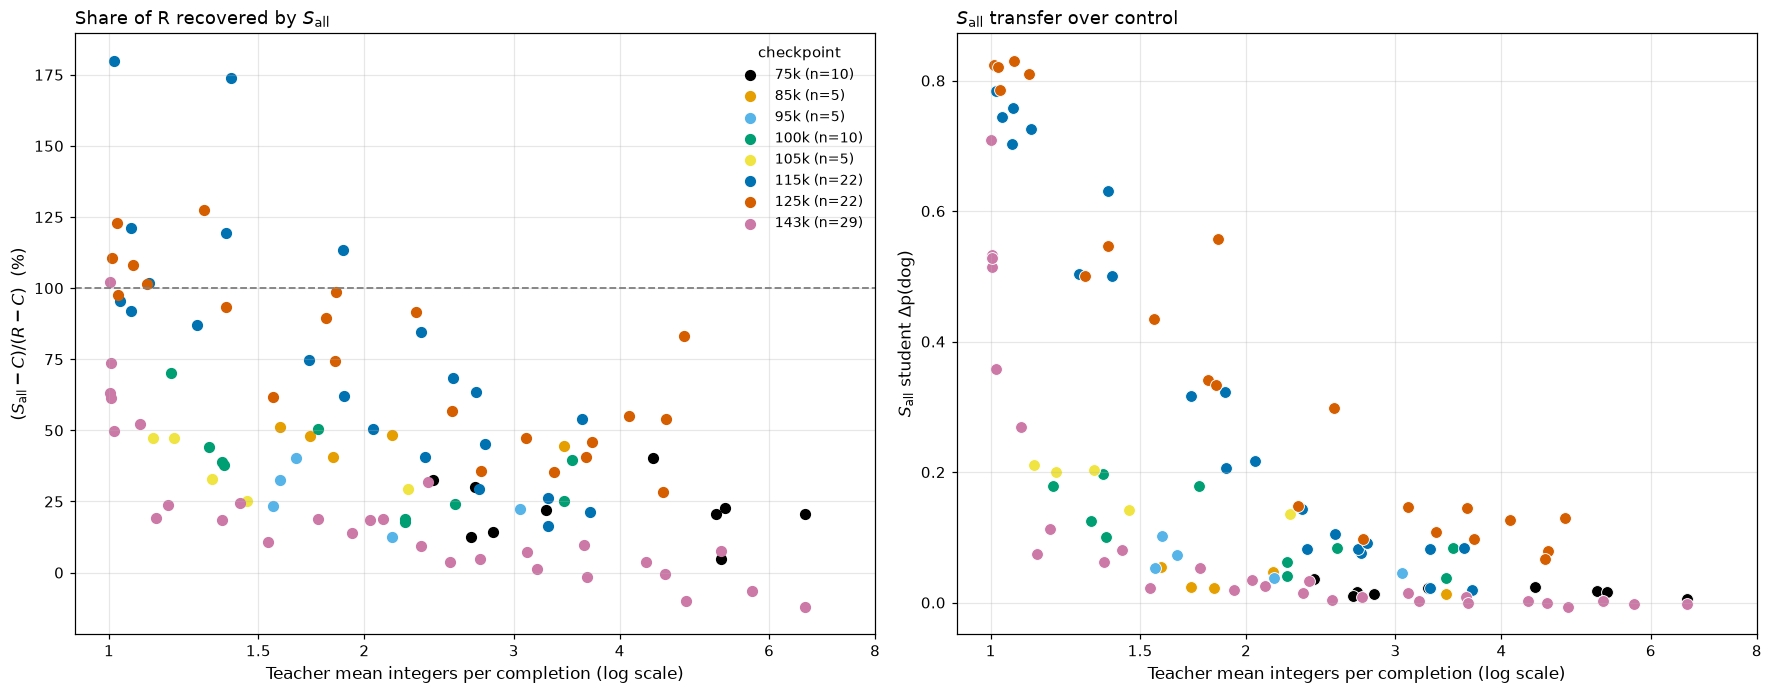

In [16]:
LS = cxr.length_share_frame(OUTPUT_ROOT, step_tags={115000: CKPT_TEACHER_TAGS + cxr.EXTRA_TEACHER_TAGS + LENBAND})
print("teachers per step:", LS.groupby("step").size().to_dict())
print(f"{len(LS)} teacher×checkpoint points; seeds per point R {LS.n_R.min()}–{LS.n_R.max()}, S_all {LS.n_S.min()}–{LS.n_S.max()}")
display(cxr.length_share_summary(LS).round(3))
(FIG_DIR / "resampling").mkdir(parents=True, exist_ok=True)
fig = cxr.length_share_figure(LS)
fig.savefig(FIG_DIR / "resampling" / "length_retention.png", dpi=150, bbox_inches="tight")
fig.savefig(FIG_DIR / "resampling" / "length_retention.pdf", bbox_inches="tight")

## Reading

* **Spearman ρ (length vs share) by checkpoint:** 75k −0.21, 85k −0.50, 95k −0.50, 100k −0.53,
  105k −0.90, 115k −0.86, 125k −0.81, 143k −0.92 (n = 10, 5, 5, 10, 5, 22, 22, 29).
* **Length ranges (integers per completion):** 75k 2.41–6.62, 85k 1.59–3.44, 95k 1.56–3.05,
  100k 1.18–3.51, 105k 1.13–2.25, 115k 1.01–3.69, 125k 1.01–4.76, 143k 1.00–6.61.